# 10 · Multiple testing, selection, and stopping

A valid p-value for one preplanned test can become misleading when it is selected from many analyses or repeatedly checked until it is small. Evaluate the whole procedure that produced a claim, not just the final calculation.

```mermaid
flowchart TD
    A[Many opportunities to claim a result] --> B[Multiple outcomes or comparisons]
    A --> C[Select the most promising analysis]
    A --> D[Keep collecting until significant]
    B --> E[Define family and error criterion]
    C --> E
    D --> F[Calibrate sequential design or fix stopping]
    E --> G[Bonferroni, Holm, or BH]
    G --> H[Report the full analysis and effects]
    F --> H
```

**Learning route:** multiplicity → FWER versus FDR → adjustment → selection → optional stopping. Prerequisites: [p-values](../05_P-Values_for_Confidence_Quantification/05_P-Values_for_Confidence_Quantification.md) and [power](../09_Power_and_Power_Analysis/09_Power_and_Power_Analysis.md).

## 1. Twenty chances to find a surprise

Imagine testing twenty independent sensor settings, none of which truly changes average accuracy. Each valid continuous test rejects its null with probability $\alpha=0.05$. The chance of **no** false rejection is $(1-0.05)^{20}$. Therefore,

$$P(\text{at least one false rejection})=1-0.95^{20}\approx0.6415.$$

This is not the probability that every test is wrong. The expected number of false rejections is $20(0.05)=1$. An expected count, a probability of any error, and a fraction among reported discoveries are different quantities.

The product formula requires independence. Tests using a shared control group are correlated, so that exact expression need not apply. Linearity of expectation still gives the sum of individual false-positive probabilities, without needing independence. The broader lesson—that more opportunities can raise the chance of at least one misleading result—remains.

![Family error probability as the number of independent tests increases](figure/multiple_opportunities.png)

**Notebook setup.** Run all cells from top to bottom. Figures are saved in this chapter's `figure/` folder. Restart the kernel and run all after changing a simulation. See the repository README for installation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

# Works when Jupyter starts in either this chapter or the repository root.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "scripts" / "build_notebooks.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the cloned course repository.")
FIGURE_DIR = ROOT / '10_P-Values_Pitfalls' / "figure"
FIGURE_DIR.mkdir(exist_ok=True)
plt.rcParams.update({
    "figure.figsize": (9, 4.8), "figure.dpi": 110,
    "font.size": 11, "axes.titlesize": 14, "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#087E8B", "#D55E00", "#7251A2", "#4477AA"]),
    "savefig.facecolor": "white", "axes.facecolor": "#FAFBFC",
})
TEAL, ORANGE, PURPLE = "#087E8B", "#D55E00", "#7251A2"

def save_figure(fig, name):
    """Save the exact figure used by Markdown and display it in the notebook."""
    fig.savefig(FIGURE_DIR / f"{name}.png", dpi=180, bbox_inches="tight")
    fig.savefig(FIGURE_DIR / f"{name}.svg", bbox_inches="tight")
    display(fig)
    plt.close(fig)

print("All datasets in this notebook are synthetic teaching examples.")


All datasets in this notebook are synthetic teaching examples.


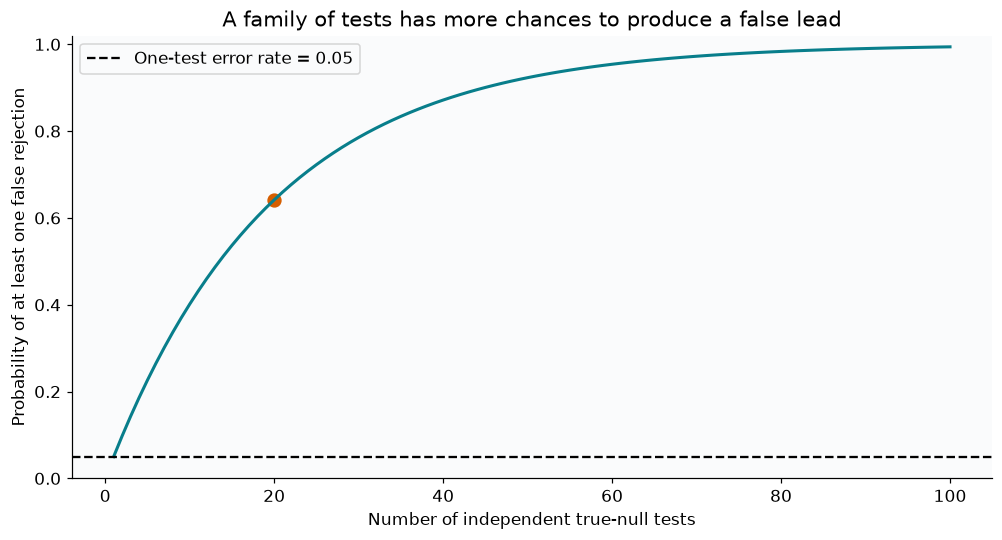

20-test FWER: 0.6415140775914581 expected false rejections: 1.0


In [2]:
m = np.arange(1,101)
fig, ax = plt.subplots(layout="constrained")
ax.plot(m,1-.95**m,lw=2)
ax.scatter([20],[1-.95**20],color=ORANGE,s=70)
ax.axhline(.05,color="black",ls="--",label="One-test error rate = 0.05")
ax.set(xlabel="Number of independent true-null tests",ylabel="Probability of at least one false rejection",
       ylim=(0,1.02),title="A family of tests has more chances to produce a false lead")
ax.legend()
save_figure(fig,"multiple_opportunities")
print("20-test FWER:",1-.95**20,"expected false rejections:",20*.05)

## 2. Name the error rate you want to control

Let $V$ be the number of false rejections and $R$ the number of all rejections in a prespecified family.

| Criterion | Definition | Interpretation across repeated families |
|---|---|---|
| Family-wise error rate, FWER | $P(V\ge1)$ | Probability of at least one false rejection |
| False discovery rate, FDR | $E[V/\max(R,1)]$ | Expected fraction of false discoveries among rejections, with zero when there are none |

FWER control is useful when even one false claim in the family is costly. FDR control is useful for exploratory screening when a controlled average proportion of false leads is acceptable and follow-up validation is planned. FDR at 0.05 does not guarantee that at most 5% of discoveries in **this particular dataset** are false, and does not give each discovery a 95% probability of being true.

When all nulls are true, every nonempty set of rejections is entirely false. Then $V/\max(R,1)$ is either zero or one, so FDR equals FWER. When some effects are real, these criteria can differ substantially.

Define the family from the scientific claims and analysis plan. Do not shrink it after seeing which outcomes look favorable. Counting only the p-values printed in a report ignores other selection opportunities.

## 3. Bonferroni: a simple bound

For $m$ tests, compare each raw p-value with $\alpha/m$, or equivalently compare adjusted values

$$p_i^{\mathrm{Bonf}}=\min(1,mp_i)$$

with $\alpha$. These are the same decision rule, not two ways with different power. The union bound gives $P(V\ge1)\le\sum_{i\in H_0}P(p_i\le\alpha/m)\le\alpha$. Valid individual p-values suffice; arbitrary dependence is allowed.

Bonferroni can be conservative, especially with many correlated tests, but its transparent guarantee can be appropriate. It does not mean that 5% of all tests will be false positives after adjustment; it bounds the probability of **any** false rejection in the family.

## 4. Holm: a step-down FWER procedure

Sort the raw p-values as $p_{(1)}\le\cdots\le p_{(m)}$. Compare the smallest with $\alpha/m$. If it passes, compare the next with $\alpha/(m-1)$, continuing until the first failure. Then stop rejecting.

The adjusted values are

$$p_{(i)}^{\mathrm{Holm}}=\min\!\left(1,\max_{j\le i}(m-j+1)p_{(j)}\right).$$

The running maximum preserves the ordering needed for the step-down rule. Restore the original test order before reporting. Holm controls FWER under arbitrary dependence for valid p-values and is never less powerful than ordinary Bonferroni for the same family.

## 5. Benjamini–Hochberg: a step-up FDR procedure

For desired FDR level $q$, find the **largest** rank $k$ satisfying $p_{(k)}\le kq/m$, then reject all hypotheses up to that rank. If none qualifies, reject none. Standard BH control holds under independence and certain forms of positive dependence; it is not a universal guarantee under arbitrary dependence. Benjamini–Yekutieli is a more conservative option for general dependence.

Adjusted BH values can be calculated with a reverse running minimum:

$$p_{(i)}^{\mathrm{BH}}=\min\!\left(1,\min_{j\ge i}\frac{m}{j}p_{(j)}\right).$$

Use the complete defined family. BH is a procedure that controls an error criterion; FDR is the criterion itself, not a synonym for every p-value adjustment.

### Worked example

For five planned comparisons with p-values 0.001, 0.012, 0.021, 0.040, and 0.200:

| Raw p | Bonferroni | Holm | BH |
|---:|---:|---:|---:|
| 0.001 | 0.005 | 0.005 | 0.005 |
| 0.012 | 0.060 | 0.048 | 0.030 |
| 0.021 | 0.105 | 0.063 | 0.035 |
| 0.040 | 0.200 | 0.080 | 0.050 |
| 0.200 | 1.000 | 0.200 | 0.200 |

At a rule of adjusted p $\le0.05$, Bonferroni rejects one, Holm two, and BH four. BH's additional discoveries reflect a different error criterion; they are not evidence that it dominates a FWER procedure for every purpose.

In [3]:
from statsmodels.stats.multitest import multipletests
raw = np.array([.001,.012,.021,.04,.2])
m = len(raw)
bonf = np.minimum(1,m*raw)
holm = np.minimum(1,np.maximum.accumulate((m-np.arange(m))*raw))
bh = np.minimum(1,np.minimum.accumulate((m*raw/np.arange(1,m+1))[::-1])[::-1])
for method,manual in [("bonferroni",bonf),("holm",holm),("fdr_bh",bh)]:
    assert np.allclose(manual,multipletests(raw,method=method)[1])
display(pd.DataFrame({"raw":raw,"Bonferroni":bonf,"Holm":holm,"BH":bh}))
assert np.allclose(holm,[.005,.048,.063,.08,.2])

,raw,Bonferroni,Holm,BH
0,0.001,0.005,0.005,0.005
1,0.012,0.060,0.048,0.030
2,0.021,0.105,0.063,0.035
3,0.040,0.200,0.080,0.050
4,0.200,1.000,0.200,0.200


The next simulation creates families with 80 true nulls and 20 real effects. It estimates both FWER and FDR for each method, showing why they should not be conflated. The simulated truths are known, which permits calculating $V$; in real data we do not know which rejections are false.

With the notebook's fixed seed and 3,000 families, the results are approximately:

| Method | Estimated FWER | Estimated FDR | Mean discoveries per family |
|---|---:|---:|---:|
| Bonferroni | 0.041 | 0.0062 | 6.38 |
| Holm | 0.044 | 0.0065 | 6.50 |
| BH | 0.410 | 0.0400 | 12.79 |

BH often makes at least one false discovery here, while maintaining a small average false fraction among its larger discovery sets. That is consistent with its FDR target. FWER and FDR are estimated across repetitions; no row guarantees the composition of an individual set of discoveries. Change the fraction of true nulls or the effect size to see why the distinction matters.

In [4]:
rng = np.random.default_rng(1010)
families,tests_per_family,true_nulls = 3000,100,80
z = rng.normal(size=(families,tests_per_family))
z[:,true_nulls:] += 3
p_matrix = 2*stats.norm.sf(np.abs(z))
# Apply the preceding formulas to all families at once. Each row is one family.
# The row-wise sort retains the identity of each test so false rejections can
# still be counted against the known simulation truth after adjustment.
order = np.argsort(p_matrix,axis=1)
sorted_p = np.take_along_axis(p_matrix,order,axis=1)
ranks = np.arange(1,tests_per_family+1)
adjusted_sorted = {
    "bonferroni": np.minimum(1,tests_per_family*sorted_p),
    "holm": np.minimum(1,np.maximum.accumulate((tests_per_family-ranks+1)*sorted_p,axis=1)),
    "fdr_bh": np.minimum(1,np.minimum.accumulate(
        (tests_per_family*sorted_p/ranks)[:,::-1],axis=1)[:,::-1]),
}
inverse_order = np.argsort(order,axis=1)
rows = []
for method,sorted_adjustment in adjusted_sorted.items():
    adjusted = np.take_along_axis(sorted_adjustment,inverse_order,axis=1)
    # Independent library checks also verify restoration to original test order.
    for i in [0,1,17,2999]:
        assert np.allclose(adjusted[i],multipletests(p_matrix[i],method=method)[1])
    rejection = adjusted<=.05
    false = rejection[:,:true_nulls].sum(axis=1)
    total = rejection.sum(axis=1)
    rows.append([method,np.mean(false>0),np.mean(false/np.maximum(total,1)),np.mean(total)])
display(pd.DataFrame(rows,columns=["method","estimated_FWER","estimated_FDR","mean_discoveries"]))
print("These are Monte Carlo estimates, not guarantees for one realized family.")

,method,estimated_FWER,estimated_FDR,mean_discoveries
0,bonferroni,0.041,0.006176,6.376333
1,holm,0.044,0.006494,6.501000
2,fdr_bh,0.410,0.039992,12.785000


These are Monte Carlo estimates, not guarantees for one realized family.


## 6. Selection includes more than explicit tests

Trying many outcomes, transformations, subgroups, covariate sets, exclusions, or time windows and reporting only the most favorable result changes the procedure. Inspecting twenty plots and testing only the clearest-looking difference still uses the same outcomes to select an unusually favorable case.

Predefine the principal analysis and keep a record of alternatives. Distinguish exploratory patterns from confirmatory claims. New independent data can test a selected hypothesis without reusing the selection noise. A simple adjustment of the few surviving p-values does not account for an unrecorded, much larger search.

Selection also inflates reported effects: among many noisy estimates, the most extreme is likely to include a favorable noise component. This “winner's curse” is especially serious when power is low. An adjusted p-value addresses a testing error criterion; it does not automatically remove bias in the selected effect estimate.

## 7. Optional stopping changes the experiment

Repeatedly adding observations and applying a fixed-sample 0.05 threshold creates repeated opportunities for rejection. The problem is not simply that successive tests are dependent. Even independent tests would create multiplicity; the full stopping rule must be reflected in calibration.

The notebook simulates a true zero mean with known SD 1. It compares one planned test at $n=200$ with ten looks at $n=20,40,\ldots,200$, stopping whenever $p\le0.05$. The latter rule produces more false positives even though each fixed-$n$ z-test is individually calibrated.

![Fixed-sample and repeated-look false-positive rates](figure/optional_stopping.png)

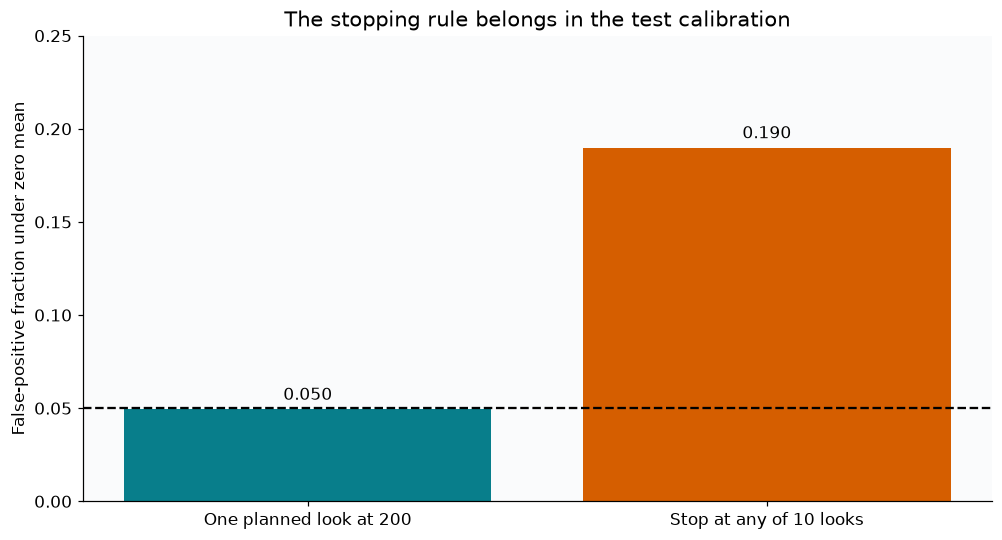

Fixed: 0.0495 Repeated looks: 0.18991666666666668


In [5]:
rng = np.random.default_rng(1011)
repetitions,max_n = 12000,200
observations = rng.normal(size=(repetitions,max_n))
cumulative = observations.cumsum(axis=1)
looks = np.arange(20,201,20)
z_at_looks = cumulative[:,looks-1]/np.sqrt(looks)
p_at_looks = 2*stats.norm.sf(np.abs(z_at_looks))
fixed_rate = np.mean(p_at_looks[:,-1]<=.05)
any_rate = np.mean(np.any(p_at_looks<=.05,axis=1))
fig, ax = plt.subplots(layout="constrained")
ax.bar(["One planned look at 200","Stop at any of 10 looks"],[fixed_rate,any_rate],color=[TEAL,ORANGE])
ax.axhline(.05,color="black",ls="--")
ax.set(ylabel="False-positive fraction under zero mean",ylim=(0,max(.25,any_rate+.04)),title="The stopping rule belongs in the test calibration")
for i,rate in enumerate([fixed_rate,any_rate]): ax.text(i,rate+.005,f"{rate:.3f}",ha="center")
save_figure(fig,"optional_stopping")
print("Fixed:",fixed_rate,"Repeated looks:",any_rate)

Choose a fixed stopping rule or a valid sequential method, such as a prespecified group-sequential design with calibrated boundaries. Sequential analysis can be valid; it is not necessary to ban all interim looks. A prior power calculation alone does not protect error rates if the study later ignores its planned stopping rule.

## 8. Practice

1. What is the chance of at least one false positive in ten independent true-null tests at 0.05? What is the expected count?
2. For raw p-values 0.004, 0.020, 0.030, calculate Holm-adjusted values and state the rejections at 0.05.
3. A BH procedure at $q=0.05$ produces twenty discoveries. Does it guarantee at most one false discovery?
4. An analyst checks fifty plots but reports only one p-value. Is the relevant selection process necessarily a single test?
5. Does multiplying all p-values by $m$ give a power advantage over comparing them with $\alpha/m$?

## 9. Worked answers

1. $1-0.95^{10}\approx0.4013$; the expected count is $10(0.05)=0.5$.
2. Multiply the sorted p-values by 3, 2, 1 to get 0.012, 0.040, 0.030. The running maximum gives **0.012, 0.040, 0.040**. All three reject. Forgetting the running maximum gives incorrect adjusted values.
3. No. The guarantee concerns the expected false-discovery proportion over repeated families under the procedure's conditions, not a deterministic limit for one family.
4. No. The visual selection can use the same outcome information as many explicit tests. The selection process must be accounted for.
5. No. Those two Bonferroni formulations are algebraically equivalent.

In [6]:
exercise_adjusted = multipletests([.004,.020,.030],method="holm")[1]
assert np.allclose(exercise_adjusted,[.012,.040,.040])
print("Practice 1 FWER:",1-.95**10)
print("Practice 2 Holm:",exercise_adjusted)

Practice 1 FWER:

 0.4012630607616213
Practice 2 Holm: [0.012 0.04  0.04 ]


## References and next step

Reading connection: Starmer (2026), Chapter 10, [SQ](../Reference.md#sq-statquest). Interpretation: [ASA statement](https://www.amstat.org/asa/files/pdfs/p-valuestatement.pdf). Algorithms and dependence conditions: [statsmodels multiple-testing methods](https://www.statsmodels.org/stable/generated/statsmodels.stats.multitest.multipletests.html). Original papers for Holm and BH are listed in [References](../Reference.md#multiple-testing).

Next: [11 · ANOVA and ANCOVA](../11_Anova_and_Ancova/11_Anova_and_Ancova.md).